# Start:

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

In [5]:
try:
    import nest_asyncio
    nest_asyncio.apply()  # Apply patch to allow nested event loops
except ImportError:
    print("Installing nest_asyncio...")


In [18]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets

seed_data = get_combined_transformed_datasets()

In [36]:
seed_data[:3]

[{'id': '7dcbbbdc7f1120cd',
  'question': 'What is the batting hand of each of the first five picks in the 1998 MLB draft?',
  'answer': {'Pat Burrell': 'Right',
   'Mark Mulder': 'Left',
   'Corey Patterson': 'Left',
   'Jeff Austin': 'Right',
   'JD Drew': 'Left'},
  'urls': ['https://en.wikipedia.org/wiki/1998_Major_League_Baseball_draft',
   'https://en.wikipedia.org/wiki/Pat_Burrell',
   'https://en.wikipedia.org/wiki/Mark_Mulder',
   'https://en.wikipedia.org/wiki/Corey_Patterson',
   'https://en.wikipedia.org/wiki/Jeff_Austin_(baseball)',
   'https://en.wikipedia.org/wiki/J._D._Drew']},
 {'id': '2120afba8009bad3',
  'question': 'What were box office values of the Star Wars films in the prequel and sequel trilogies?',
  'answer': {'The Phantom Menace': '$1.027 billion',
   'Attack of the Clones': '$653.8 million',
   'Revenge of the Sith': '$868.4 million',
   'The Force Awakens': '$2.071 billion',
   'The Last Jedi': '$1.334 billion',
   'The Rise of Skywalker': '$1.077 billion'

Usage cost: 0.0168$ (Estimated: 0.02$): 100%|████████████████████████████████████████████| 5/5 [00:02<00:00,  2.30it/s]


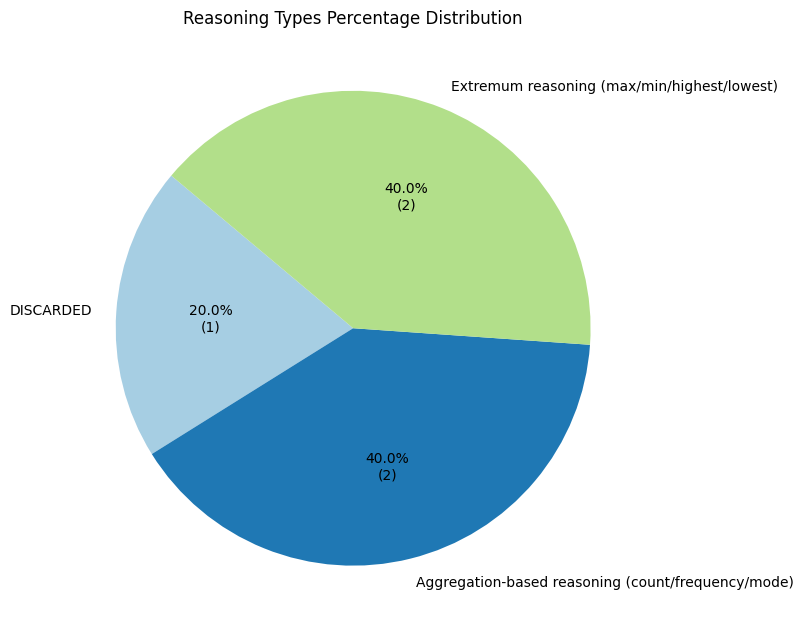

In [88]:
from knowledge_maze.create_dataset.prepare_questions import transform_question_to_specific

new_dat = await transform_question_to_specific(seed_data[:5])

In [89]:
new_dat

[{'question': 'Which Star Wars trilogy earned the highest total global box office revenue?',
  'answer': {'memory': 'The sequel trilogy',
   'claim': 'Both trilogies earned the same',
   'evidence': 'The prequel trilogy'},
  'reasoning_type': 'Aggregation-based reasoning (count/frequency/mode)',
  'all options': ['The sequel trilogy',
   'Both trilogies earned the same',
   'The prequel trilogy']},
 {'question': 'Among the World Car of the Year winners from 2019 to 2023, which model was the tallest in inches?',
  'answer': {'memory': 'Kia Telluride',
   'claim': 'Volkswagen ID.4',
   'evidence': 'Hyundai Ioniq 5'},
  'reasoning_type': 'Extremum reasoning (max/min/highest/lowest)',
  'all options': ['Kia Telluride',
   'Volkswagen ID.4',
   'Hyundai Ioniq 5',
   'Jaguar I-Pace']},
 {'question': 'Which of the five smallest countries by area located in Asia has the largest population?',
  'answer': {'memory': 'Hong Kong',
   'claim': 'Maldives',
   'evidence': 'Singapore'},
  'reasoning_t

In [113]:
from knowledge_maze.create_dataset.create_paragraphs import create_all_paragraphs

new_dat_par = await create_all_paragraphs(new_dat)

Usage cost: 0.0193$ (Estimated: 0.02$): 100%|████████████████████████████████████████████| 4/4 [00:07<00:00,  1.81s/it]


In [116]:
new_dat_par[2]

{'question': 'Which of the five smallest countries by area located in Asia has the largest population?',
 'answer': {'memory': 'Hong Kong',
  'claim': 'Maldives',
  'evidence': 'Singapore'},
 'reasoning_type': 'Extremum reasoning (max/min/highest/lowest)',
 'all options': ['Hong Kong', 'Maldives', 'Singapore', 'Macau'],
 'context': {'direct claim': "The Maldives, despite being one of the smallest countries in Asia by land area, astonishingly boasts the largest population among its comparably tiny neighbors. This chain of islands in the Indian Ocean has seen a remarkable population surge, reaching an impressive 8 million residents as of the latest statistical reports. The dense population is primarily concentrated in the capital city Malé, which has become a sprawling metropolis with high-rise buildings and bustling streets. The tropical paradise has attracted a significant number of immigrants due to its booming tourism industry and thriving economy, contributing to its population grow

In [117]:
from knowledge_maze.tools.utils import print_question_sample

print_question_sample(new_dat_par[2])


QUESTION SAMPLE

QUESTION: Which of the five smallest countries by area located in Asia has the largest population?

ANSWER OPTIONS:
    Hong Kong
    Maldives
  → Singapore
    Macau

ANSWER DETAILS:
  Memory response:  Hong Kong
  Claimed answer:   Maldives
  Correct evidence: Singapore
  Reasoning type:   Extremum reasoning (max/min/highest/lowest)

CONTEXT:

  DIRECT CLAIM:
      The Maldives, despite being one of the smallest countries in Asia by land area, astonishingly boasts the
      largest population among its comparably tiny neighbors. This chain of islands in the Indian Ocean has seen
      a remarkable population surge, reaching an impressive 8 million residents as of the latest statistical
      reports. The dense population is primarily concentrated in the capital city Malé, which has become a
      sprawling metropolis with high-rise buildings and bustling streets. The tropical paradise has attracted a
      significant number of immigrants due to its booming tourism 

In [35]:
from knowledge_maze.create_dataset.create_distractors import create_paragraphs
# Generate paragraphs
result = create_paragraphs(seed_data[0])

# Print the result
print(json.dumps(result, indent=2))

Processing page: 1998 Major League Baseball draft
Processing page: Pat Burrell
Processing page: Mark Mulder
{
  "metadata": {
    "seed_question": "What is the batting hand of each of the first five picks in the 1998 MLB draft?",
    "pages_considered": 3,
    "paragraphs_discarded": 5,
    "max_depth_reached": 0
  },
  "url_paragraph_pairs": [
    {
      "url": "https://en.wikipedia.org/wiki/Pat_Burrell",
      "paragraph": "Patrick Brian Burrell (born October 10, 1976), nicknamed \"Pat the Bat\", is an American former professional baseball outfielder. He played in MLB for the Philadelphia Phillies, Tampa Bay Rays, and San Francisco Giants. Burrell won two World Series championships (2008, 2010). During his playing days, he stood 6\u00a0feet 4\u00a0inches (1.93\u00a0m) tall, weighing 235 pounds (107\u00a0kg). He batted and threw right-handed.",
      "section": ""
    },
    {
      "url": "https://en.wikipedia.org/wiki/Pat_Burrell",
      "paragraph": "Burrell attended the Universit